# Import libraries

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas  as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import pickle
import joblib

# data Understanding

**Load data**

In [ ]:
file_path = '/content/drive/MyDrive/rideflow_AI/source_data/raw_data.csv'
data = pd.read_csv(file_path)


In [ ]:
data.shape

(2160266, 21)

In [ ]:
data.columns

Index(['ride_id', 'Booking_time', 'pickup_zone', 'drop_zone', 'driver_id',
       'customer_id', 'trip_km', 'base_fare', 'surge_multiplier', 'total_fare',
       'customer_rating', 'estimated_trip_duration_min',
       'actual_trip_duration_min', 'ride_status', 'reason_cancellation',
       'traffic_level', 'weather', 'driver_status', 'feedback_text',
       'driver_rating'],
      dtype='object')

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2160266 entries, 0 to 2160265
Data columns (total 20 columns):
 #   Column                       Dtype  
---  ------                       -----  
 0   ride_id                      int64  
 1   Booking_time                 object 
 2   pickup_zone                  object 
 3   drop_zone                    object 
 4   driver_id                    int64  
 5   customer_id                  int64  
 6   trip_km                      float64
 7   base_fare                    float64
 8   surge_multiplier             float64
 9   total_fare                   float64
 10  customer_rating              float64
 11  estimated_trip_duration_min  int64  
 12  actual_trip_duration_min     int64  
 13  ride_status                  object 
 14  reason_cancellation          object 
 15  traffic_level                object 
 16  weather                      object 
 17  driver_status                object 
 18  feedback_text                object 
 19  

In [ ]:
# Seperate numerical and categorical features

numerical_cols = data.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_cols = data.select_dtypes(include=['object']).columns.tolist()

print(f"Numerical columns ({len(numerical_cols)}): {numerical_cols}")
print(f"Categorical columns ({len(categorical_cols)}): {categorical_cols}")

Numerical columns (12): ['ride_id', 'trip_km', 'driver_id', 'customer_id', 'fare_price', 'surge_multiplier', 'driver_rating', 'customer_rating', 'estimated_trip_duration_min', 'actual_trip_duration_min', 'estimated_driver_arrival_min', 'actual_driver_arrival_min']
Categorical columns (10): ['Booking_time', 'pickup_zone', 'drop_zone', 'driver_location', 'ride_status', 'reason_cancellation', 'traffic_level', 'weather', 'driver_status', 'feedback_text']


In [ ]:
#  count missing values
missing_count = data.isnull().sum()
# Percentage of missing values per column
missing_pct = (data.isnull().sum() / len(data)) * 100

miising_df = pd.DataFrame ({'count': missing_count, 'pct': missing_pct})
miising_df

,count,pct
ride_id,0,0.0
Booking_time,0,0.0
pickup_zone,0,0.0
drop_zone,0,0.0
driver_id,0,0.0
driver_location,0,0.0
customer_id,0,0.0
trip_km,0,0.0
base_fare,0,0.0
surge_multiplier,0,0.0


In [ ]:
#  check duplicates
data.duplicated().sum()

np.int64(0)

In [ ]:
# basic statistics
data[numerical_cols].describe()

,ride_id,driver_id,customer_id,trip_km,base_fare,surge_multiplier,total_fare,customer_rating,estimated_trip_duration_min,actual_trip_duration_min,estimated_driver_arrival_min,actual_driver_arrival_min,driver_rating
count,2.160266e+06,2.160266e+06,2.160266e+06,2.160266e+06,2.160266e+06,2.160266e+06,2.160266e+06,2.160266e+06,2.160266e+06,2.160266e+06,2.160266e+06,2.160266e+06,2.160266e+06
mean,1.080134e+06,2.750361e+04,2.247140e+04,1.230316e+01,1.986780e+02,1.231238e+00,2.466552e+02,4.039064e+00,3.251556e+01,3.957394e+01,5.422900e+00,7.382208e+00,4.076378e+00
std,6.236152e+05,1.588127e+04,1.299841e+04,6.325406e+00,1.054248e+02,1.390351e-01,1.360727e+02,3.980107e-01,1.482366e+01,1.551019e+01,4.714084e+00,7.986180e+00,3.666052e-01
min,1.000000e+00,1.000000e+00,1.000000e+00,2.500000e+00,3.749380e+01,1.000000e+00,3.750000e+01,2.020000e+00,7.000000e+00,7.000000e+00,2.000000e+00,2.000000e+00,2.010000e+00
25%,5.400672e+05,1.376000e+04,1.120400e+04,8.000000e+00,1.319997e+02,1.118100e+00,1.527600e+02,3.770000e+00,2.200000e+01,2.900000e+01,3.000000e+00,3.000000e+00,3.830000e+00
50%,1.080134e+06,2.749900e+04,2.245300e+04,1.100000e+01,1.700018e+02,1.204000e+00,2.144800e+02,4.050000e+00,3.000000e+01,3.800000e+01,4.000000e+00,4.000000e+00,4.090000e+00
75%,1.620200e+06,4.124800e+04,3.372800e+04,1.500000e+01,2.550000e+02,1.334300e+00,3.275700e+02,4.330000e+00,4.000000e+01,4.800000e+01,7.000000e+00,7.000000e+00,4.340000e+00
max,2.160266e+06,5.500000e+04,4.500000e+04,3.300000e+01,7.260376e+02,1.500000e+00,1.076430e+03,4.700000e+00,8.000000e+01,9.500000e+01,1.700000e+01,3.200000e+01,4.700000e+00


In [ ]:
# Check unique values for categorical columns
for col in categorical_cols:
    print(f"{col} : {data[col].nunique()} unique values")
    print(f"  Values: {data[col].unique()}")
    print("-" * 50)

pickup_zone : 10 unique values
  Values: ['anna_nagar' 'porur' 'velachery' 'guindy' 'saidapet' 'egmore' 'mambalam'
 'tambaram' 'besant_nagar' 'adyar']
--------------------------------------------------
drop_zone : 10 unique values
  Values: ['tambaram' 'besant_nagar' 'guindy' 'anna_nagar' 'mambalam' 'adyar'
 'velachery' 'saidapet' 'egmore' 'porur']
--------------------------------------------------
driver_location : 10 unique values
  Values: ['anna_nagar' 'porur' 'velachery' 'adyar' 'saidapet' 'guindy' 'egmore'
 'mambalam' 'tambaram' 'besant_nagar']
--------------------------------------------------
ride_status : 2 unique values
  Values: ['completed' 'cancelled']
--------------------------------------------------
reason_cancellation : 3 unique values
  Values: ['not_applicable' 'driver_cancelled' 'customer_cancelled']
--------------------------------------------------
traffic_level : 3 unique values
  Values: ['low' 'high' 'medium']
--------------------------------------------------


In [ ]:
# Check class imbalance in categorical features
for col in categorical_cols:
    print(f"{col} : {data[col].value_counts()} counts")
    print("-" * 50)

Booking_time : Booking_time
2026-01-24 19:22:25    7
2026-03-17 18:14:13    7
2026-03-26 08:13:15    7
2026-01-28 09:39:52    6
2026-01-26 19:48:02    6
                      ..
2026-02-02 20:38:35    1
2026-02-02 20:38:31    1
2026-02-02 20:38:29    1
2026-02-02 20:38:12    1
2026-02-02 20:39:03    1
Name: count, Length: 1810626, dtype: int64 counts
--------------------------------------------------
pickup_zone : pickup_zone
anna_nagar      281263
guindy          256539
velachery       237518
adyar           236384
egmore          215477
mambalam        214923
besant_nagar    198819
porur           195056
tambaram        173780
saidapet        150507
Name: count, dtype: int64 counts
--------------------------------------------------
drop_zone : drop_zone
anna_nagar      271126
guindy          254100
adyar           236245
velachery       235333
egmore          217558
mambalam        217046
porur           196934
besant_nagar    196863
tambaram        178002
saidapet        157059
Name

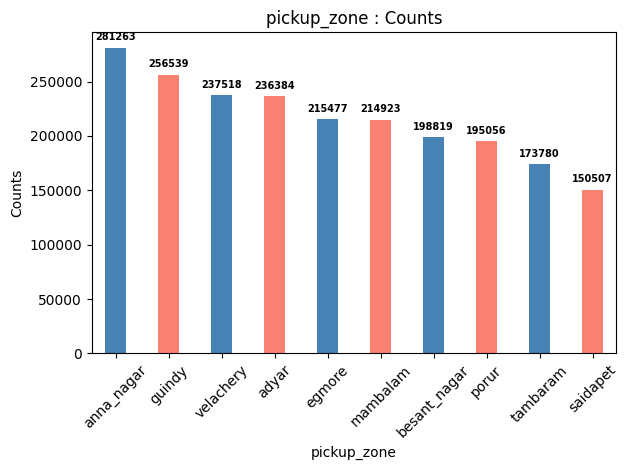

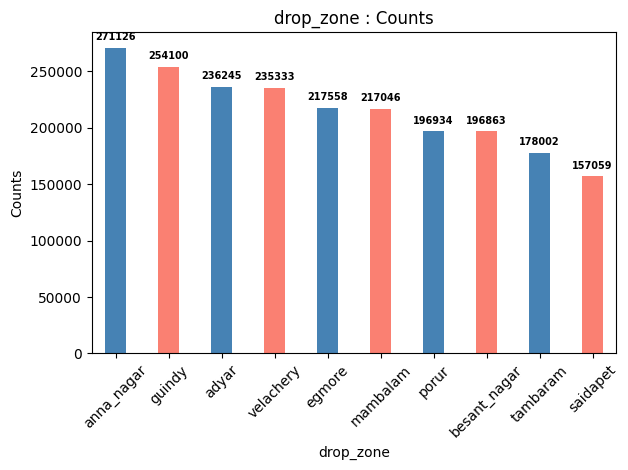

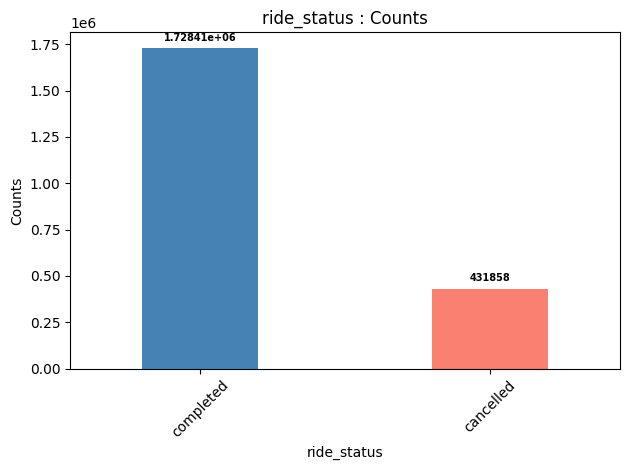

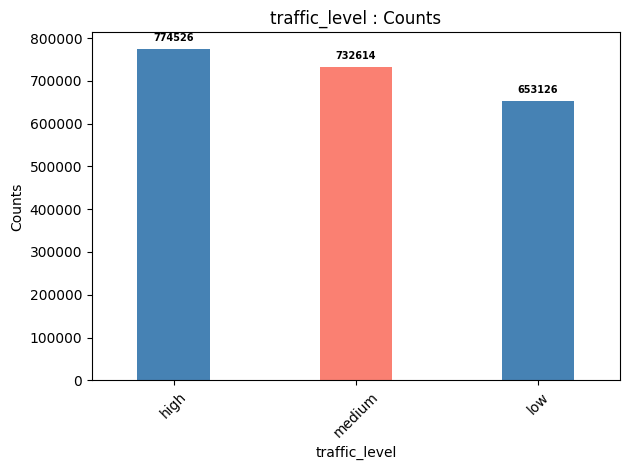

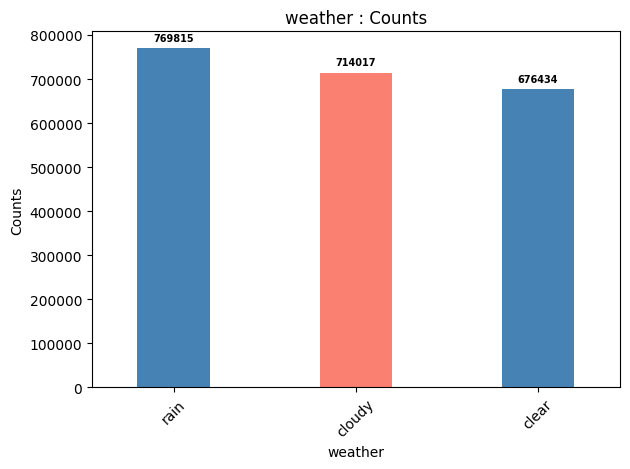

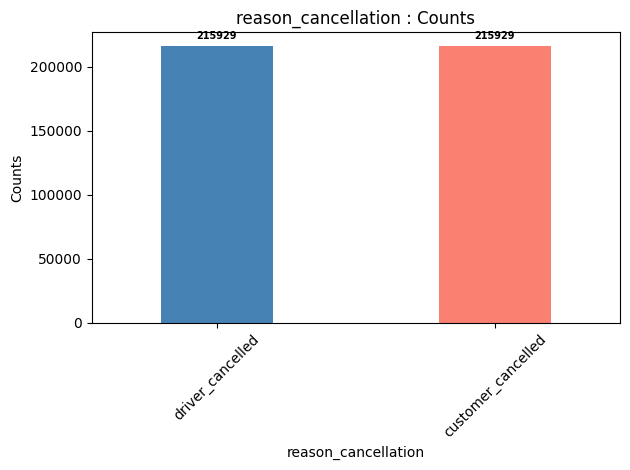

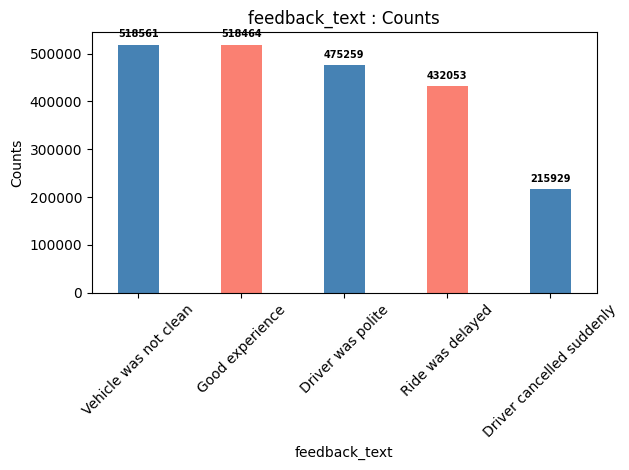

In [ ]:
# Check class imbalance for classification
import matplotlib.pyplot as plt

categorical_cols = ['pickup_zone', 'drop_zone', 'ride_status', 'traffic_level', 'weather','reason_cancellation', 'feedback_text']

for col in categorical_cols:
    fig, ax = plt.subplots()
    counts = data[col].value_counts()
    counts.plot(kind='bar', ax=ax, color=['steelblue', 'salmon'],width=0.4)
    ax.bar_label(ax.containers[0], padding=4,fontsize=7,fontweight='bold')
    ax.set_title(f'{col} : Counts')
    ax.set_xlabel(col)
    ax.set_ylabel("Counts")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()


In [ ]:
# Final summary of data exploration
print(f"Total Rows: {data.shape[0]}")
print(f"Total Columns: {data.shape[1]}")
print(f"Numerical Columns: {len(numerical_cols)}")
print(f"Categorical Columns: {len(categorical_cols)}")
print(f"Total Missing Values: {data.isnull().sum().sum()}")
print(f"Total Duplicate Rows: {data.duplicated().sum()}")


Total Rows: 2160266
Total Columns: 23
Numerical Columns: 13
Categorical Columns: 9
Total Missing Values: 0
Total Duplicate Rows: 0


# Data Cleaning

In [ ]:
df= data.copy()

In [ ]:
# fixing inconsistant data types
df['Booking_time']= pd.to_datetime(df['Booking_time'])

# Update numerical and categorical columns after dtype changes
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()
time_cols = df.select_dtypes(include=["datetime64[ns]"]).columns.tolist()

print(f"Numerical columns ({len(numerical_cols)}): {numerical_cols}")
print(f"Categorical columns ({len(categorical_cols)}): {categorical_cols}")
print(f"Time columns ({len(time_cols)}): {time_cols}")


#  fixing inconsistant spaces
for col in categorical_cols:
  df[col] = df[col].str.lower()
  df[col] = df[col].str.strip()


Numerical columns (12): ['ride_id', 'driver_id', 'customer_id', 'trip_km', 'base_fare', 'surge_multiplier', 'total_fare', 'customer_rating', 'estimated_trip_duration_min', 'actual_trip_duration_min', 'estimated_driver_arrival_min', 'driver_rating']
Categorical columns (8): ['pickup_zone', 'drop_zone', 'ride_status', 'reason_cancellation', 'traffic_level', 'weather', 'driver_status', 'feedback_text']
Time columns (1): ['Booking_time']


In [ ]:
# check for inconsistant values
checks = {
    "trip_km_negative": df["trip_km"] < 0,
    "fare_price_negative": df["total_fare"] < 0,
    "surge_multiplier_nonpositive": df["surge_multiplier"] <= 0,
    "driver_rating_outside_0_5": ~df["driver_rating"].between(0, 5),
    "customer_rating_outside_0_5": ~df["customer_rating"].between(0, 5),
    'estimated_trip_duration_min': df["estimated_trip_duration_min"] < 0,
    'actual_trip_duration_min': df["actual_trip_duration_min"] < 0,

}

# print("invalid values")

for name, mask in checks.items():
    print(f"{name}: {mask.sum()} rows")

trip_km_negative: 0 rows
fare_price_negative: 0 rows
surge_multiplier_nonpositive: 0 rows
driver_rating_outside_0_5: 0 rows
customer_rating_outside_0_5: 0 rows
estimated_trip_duration_min: 0 rows
actual_trip_duration_min: 0 rows


In [ ]:
# Check skewness of all numerical columns
print(df[numerical_cols].skew().sort_values(ascending=False))

estimated_driver_arrival_min    1.594256
total_fare                      1.230085
base_fare                       1.225180
trip_km                         1.103282
estimated_trip_duration_min     0.850328
actual_trip_duration_min        0.739686
surge_multiplier                0.450016
customer_id                     0.002576
driver_id                       0.000579
ride_id                         0.000000
driver_rating                  -0.257346
customer_rating                -0.273669
dtype: float64


In [ ]:
#  check for outliers
for col in numerical_cols:
  q1= df[col].quantile(0.25)
  q3= df[col].quantile(0.75)
  iqr= q3-q1
  lower = q1 - 1.5 * iqr
  upper = q3 + 1.5 * iqr
  outliers = df[(df[col] < lower) | (df[col] > upper)][col].count()
  print(f"{col} — Outliers: {outliers} ({round(outliers/len(df)*100, 2)}%)")

ride_id — Outliers: 0 (0.0%)
driver_id — Outliers: 0 (0.0%)
customer_id — Outliers: 0 (0.0%)
trip_km — Outliers: 88768 (4.11%)
base_fare — Outliers: 76677 (3.55%)
surge_multiplier — Outliers: 0 (0.0%)
total_fare — Outliers: 65453 (3.03%)
customer_rating — Outliers: 7928 (0.37%)
estimated_trip_duration_min — Outliers: 50654 (2.34%)
actual_trip_duration_min — Outliers: 59742 (2.77%)
estimated_driver_arrival_min — Outliers: 139336 (6.45%)
driver_rating — Outliers: 8804 (0.41%)


# EDA

In [ ]:
eda_plot = df.copy()

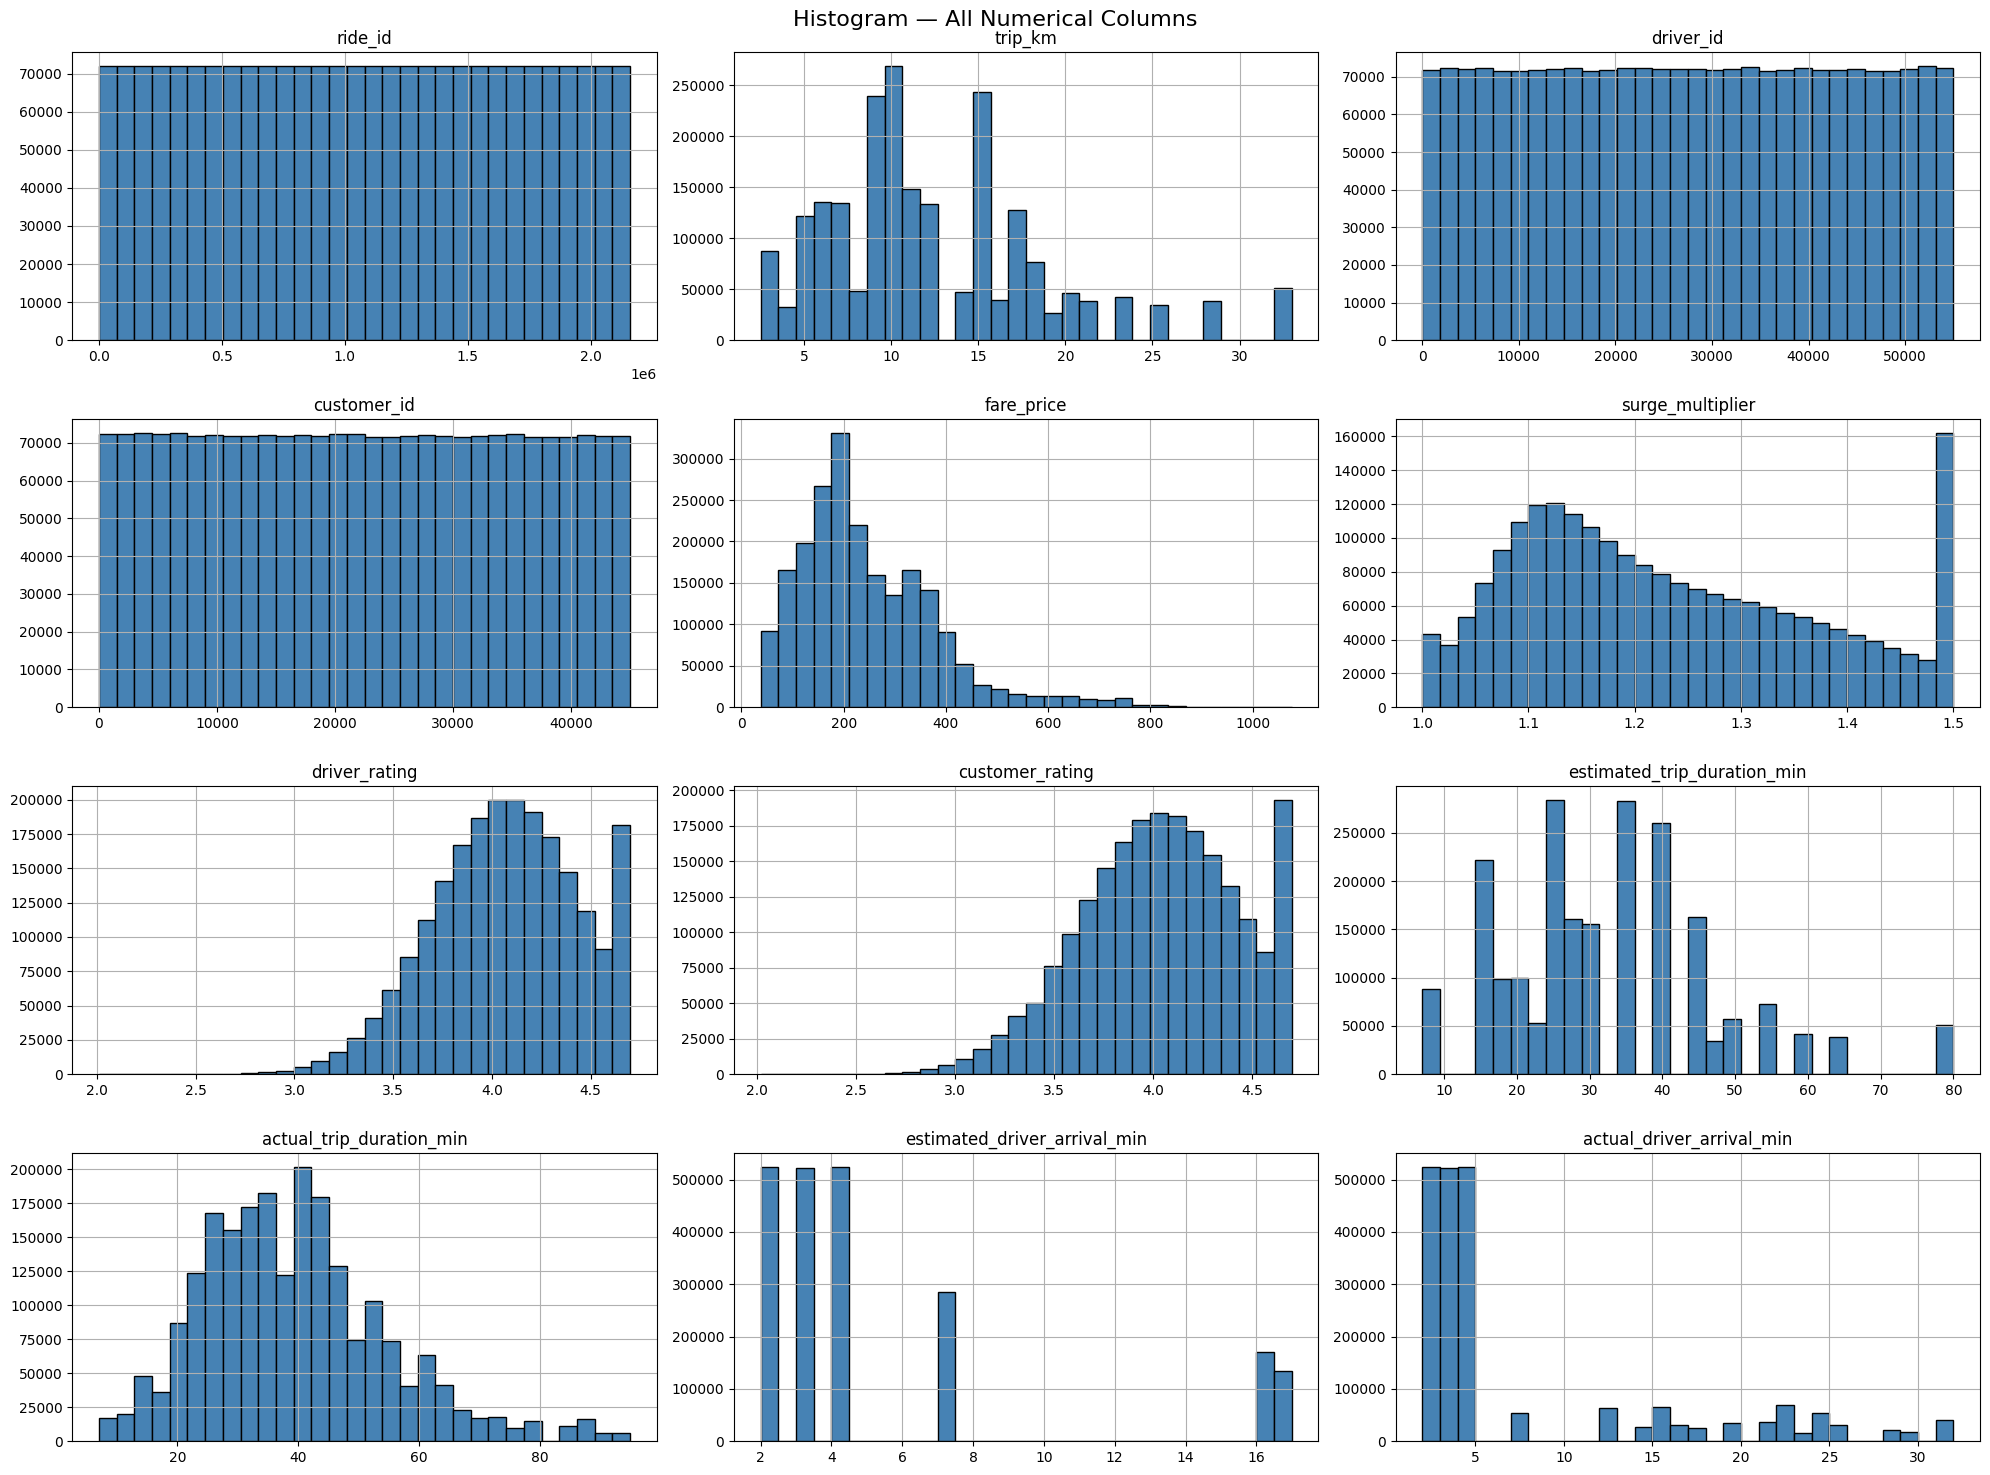

In [ ]:
eda_plot[numerical_cols].hist(bins=30, figsize=(20, 15), color='steelblue', edgecolor='black')
plt.suptitle('Histogram — All Numerical Columns', fontsize=16)
plt.tight_layout()
plt.show()

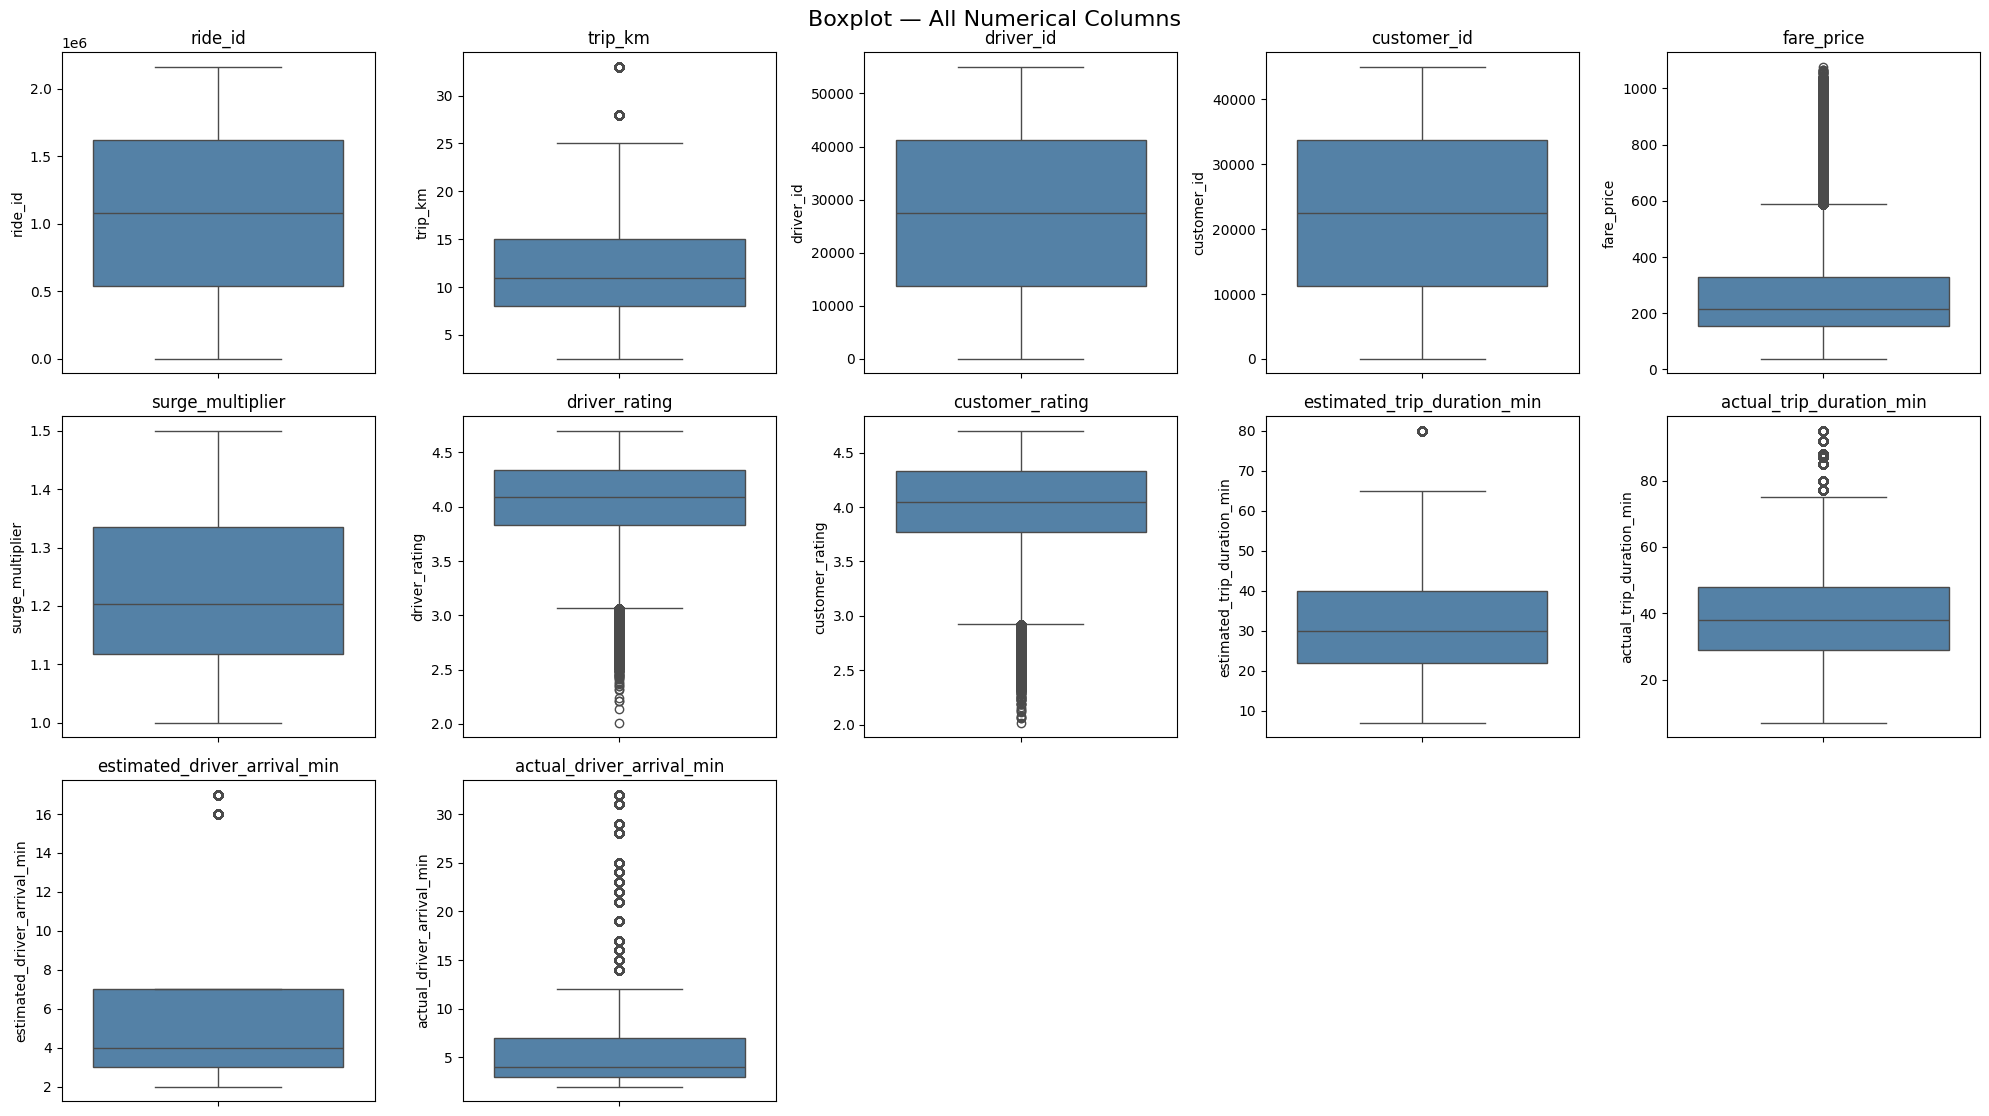

In [ ]:
# Boxplot — check spread and outliers for all numerical columns
plt.figure(figsize=(20, 15))
for i, col in enumerate(numerical_cols):
    plt.subplot(4, 5, i+1)
    sns.boxplot(y=df[col], color='steelblue')
    plt.title(col)
plt.suptitle('Boxplot — All Numerical Columns', fontsize=16)
plt.tight_layout()
plt.show()

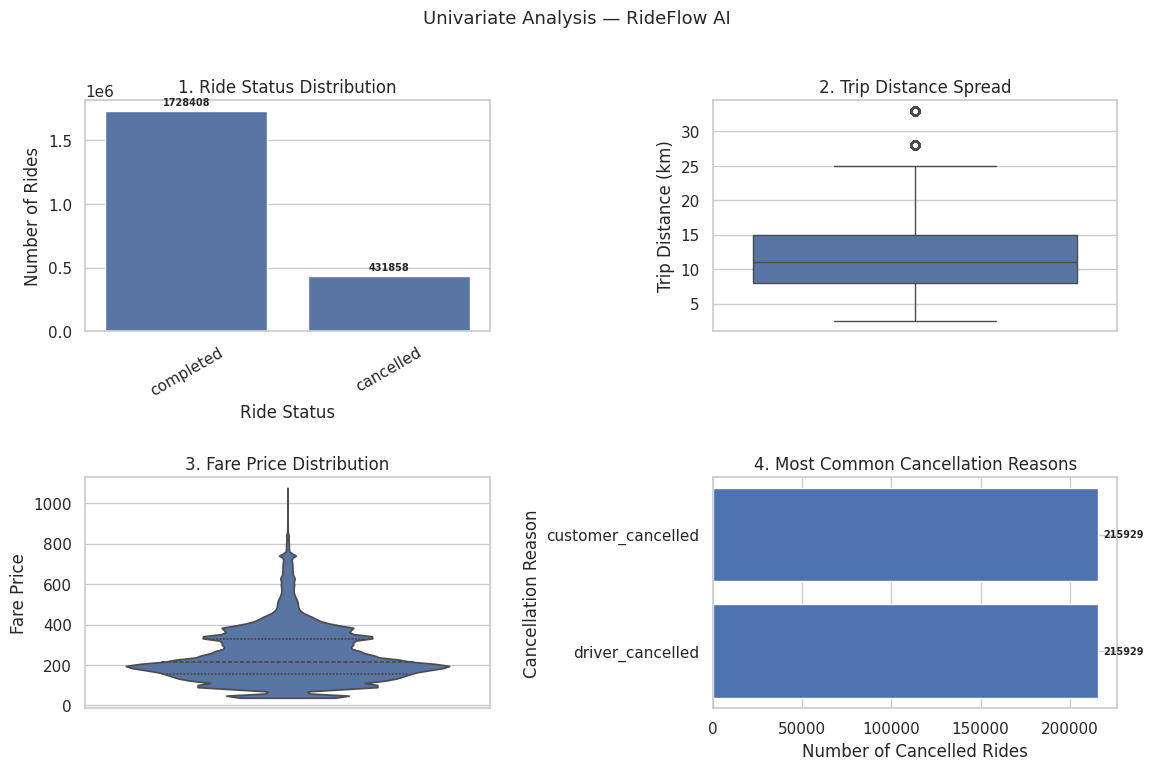

In [ ]:

sns.set_theme(style="whitegrid", context="notebook")

# Create cancellation indicator for analysis
eda_plot["is_cancelled"] = (eda_plot["ride_status"].astype("string")
    .str.contains("cancel", case=False, na=False).astype(int))

fig, axes = plt.subplots(2, 2, figsize=(12,8))
fig.suptitle("Univariate Analysis — RideFlow AI", fontsize=13)

# 1. Count of rides by ride status
status_order = eda_plot["ride_status"].value_counts().index
sns.countplot(data=eda_plot,x="ride_status",order=status_order,ax=axes[0, 0])
# Display actual counts
for container in axes[0, 0].containers:
    axes[0, 0].bar_label(container, fmt="%.0f",fontsize=7,fontweight='bold', padding=3)
axes[0, 0].set_title("1. Ride Status Distribution")
axes[0, 0].set_xlabel("Ride Status")
axes[0, 0].set_ylabel("Number of Rides")
axes[0, 0].tick_params(axis="x", rotation=30)

# 2. Trip distance distribution — boxplot
sns.boxplot(data=eda_plot,y="trip_km",ax=axes[0, 1])
axes[0, 1].set_title("2. Trip Distance Spread")
axes[0, 1].set_ylabel("Trip Distance (km)")

# 3. Fare distribution — violin plot
sns.violinplot(data=eda_plot,y="fare_price",inner="quartile",cut=0,ax=axes[1, 0])
axes[1, 0].set_title("3. Fare Price Distribution")
axes[1, 0].set_ylabel("Fare Price")

# 4. Cancellation reasons — count plot
cancelled_rows = eda_plot[eda_plot["is_cancelled"] == 1]
reason_counts = (cancelled_rows["reason_cancellation"].fillna("Not recorded")
    .astype(str).value_counts().head(10))
if len(reason_counts) > 0:
    bars = axes[1, 1].barh(reason_counts.index,reason_counts.values)
    axes[1, 1].bar_label(bars, fmt="%.0f", padding=4,fontsize=7,fontweight='bold')
    axes[1, 1].set_xlabel("Number of Cancelled Rides")
    axes[1, 1].set_ylabel("Cancellation Reason")
else:
    axes[1, 1].text(0.5, 0.5, "No cancelled rides found",ha="center",fontsize=7, va="center")
axes[1, 1].set_title("4. Most Common Cancellation Reasons")

plt.tight_layout(pad=2.0)
plt.show()

**Bivariate Analysis**

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
fig.suptitle("Bivariate Analysis — RideFlow AI", fontsize=10)

# 5. Trip distance vs fare, grouped by ride status
sns.scatterplot(data=eda_plot,x="trip_km",y="fare_price",hue="ride_status",alpha=0.65,
    s=35,ax=axes[0, 0])
axes[0, 0].set_title("5. Trip Distance vs Fare")
axes[0, 0].set_xlabel("Trip Distance (km)")
axes[0, 0].set_ylabel("Fare Price")

# 6. Estimated ETA vs actual ETA
eta_df = eda_plot.dropna(subset=["estimated_trip_duration_min", "actual_trip_duration_min"])
sns.scatterplot(data=eta_df,x="estimated_trip_duration_min",y="actual_trip_duration_min",alpha=0.5,s=30,
    ax=axes[0, 1])

# Reference line: perfect ETA prediction
if not eta_df.empty:
    max_eta = max(eta_df["estimated_trip_duration_min"].max(),eta_df["actual_trip_duration_min"].max())
    if np.isfinite(max_eta) and max_eta > 0:
        axes[0, 1].plot([0, max_eta], [0, max_eta],linestyle="--", color="red",
            label="Actual = Estimated")
        axes[0, 1].legend()

axes[0, 1].set_title("6. Estimated ETA vs Actual ETA")
axes[0, 1].set_xlabel("Estimated ETA (minutes)")
axes[0, 1].set_ylabel("Actual ETA (minutes)")

# 7. Cancellation rate by traffic level
traffic_cancel = (eda_plot.dropna(subset=["traffic_level"])
    .groupby("traffic_level", observed=True)["is_cancelled"].mean().mul(100)
    .reset_index(name="cancellation_rate_pct"))

sns.barplot(data=traffic_cancel,x="traffic_level",y="cancellation_rate_pct",ax=axes[1, 0])
# Display cancellation percentages
for container in axes[1, 0].containers:
    axes[1, 0].bar_label(container,fmt="%.1f%%",fontsize=7,fontweight='bold',padding=3)

axes[1, 0].set_title("7. Cancellation Rate by Traffic Level")
axes[1, 0].set_xlabel("Traffic Level")
axes[1, 0].set_ylabel("Cancelled Rides (%)")
axes[1, 0].tick_params(axis="x", rotation=25)

# 8. Fare by weather condition — boxplot
sns.barplot(data=eda_plot,x="weather",y="fare_price",
    estimator="mean",errorbar=None,ax=axes[1, 1])
for container in axes[1, 1].containers:
  axes[1, 1].bar_label(container,fmt="%.1f",fontsize=7,fontweight='bold',padding=3)
axes[1, 1].set_title("8. Average Fare by Weather")
axes[1, 1].set_xlabel("Weather")
axes[1, 1].set_ylabel("Average Fare")
axes[1, 1].tick_params(axis="x", rotation=25)

plt.tight_layout(pad=2.0)
plt.show()



/tmp/ipykernel_540/3505257380.py:53: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout(pad=2.0)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


KeyboardInterrupt: 

In [ ]:

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.suptitle("Multivariate Analysis — RideFlow AI", fontsize=15)

# 9. Trip distance by ride status and traffic level
sns.boxplot(data=eda_plot.dropna(subset=["trip_km", "ride_status", "traffic_level"]),
    x="ride_status",y="trip_km",hue="traffic_level",ax=axes[0, 0])
axes[0, 0].set_title("9. Trip Distance by Ride Status and Traffic Level")
axes[0, 0].set_xlabel("Ride Status")
axes[0, 0].set_ylabel("Trip Distance (km)")
axes[0, 0].legend(fontsize=8)


# 10. Estimated ETA by traffic level and ride status
sns.pointplot(data=eda_plot.dropna(subset=["traffic_level", "estimated_trip_duration_min", "ride_status"]),
    x="traffic_level",y="estimated_trip_duration_min",hue="ride_status",errorbar=None,ax=axes[0, 1])
axes[0, 1].set_title("10. Estimated ETA by Traffic and Ride Status")
axes[0, 1].set_xlabel("Traffic Level")
axes[0, 1].set_ylabel("Estimated ETA (minutes)")

# 11. Average fare by pickup zone and ride status — top 8 zones
top_zones = (eda_plot["pickup_zone"].value_counts().head(8).index)
zone_fare = eda_plot[eda_plot["pickup_zone"].isin(top_zones)].dropna(subset=["fare_price", "ride_status"])

sns.barplot(data=zone_fare,x="pickup_zone",y="fare_price",hue="ride_status",estimator="mean",
    errorbar=None,ax=axes[1, 0])

# Display average fare on each bar
for container in axes[1, 0].containers:
    axes[1, 0].bar_label(container,fmt="%.1f",padding=2,fontsize=7,color='#880808')

axes[1, 0].set_title("11. Average Fare by Pickup Zone and Ride Status")
axes[1, 0].set_xlabel("Pickup Zone")
axes[1, 0].set_ylabel("Average Fare")
axes[1, 0].tick_params(axis="x", rotation=35)
axes[1, 0].legend(title="Ride Status")

# 12. Distance vs fare, with surge multiplier and traffic
scatter_df = eda_plot.dropna(subset=["trip_km", "fare_price", "traffic_level"])
sns.scatterplot(data=scatter_df,x="trip_km",y="fare_price",hue="traffic_level",size="traffic_level",alpha=0.65,ax=axes[1, 1])
axes[1, 1].set_title("12. Trip Distance vs Fare by Traffic ")
axes[1, 1].set_xlabel("Trip Distance (km)")
axes[1, 1].set_ylabel("Fare Price")
plt.tight_layout(pad=2.0)
plt.show()

# Demand Prediction

In [ ]:
# Encoding
# encode traffic colum
traffic = {'low': 0, 'medium': 1, 'high': 2}
df['traffic_level_enc'] = df['traffic_level'].map(traffic)

# encode weather colum
climate = {'clear': 0, 'cloudy': 1, 'rain': 2}
df['weather_enc'] = df['weather'].map(climate)

# encode cancellation colum
reason = {'customer_cancelled': 0, 'driver_cancelled': 1, 'not_applicable': 2}
df['reason_cancellation_enc'] = df['reason_cancellation'].map(reason)

#encode driver status colum
status = {'available': 0, 'unavailable': 1, 'not_applicable': 2}
df['driver_status_enc'] = df['driver_status'].map(status)

# encode ride status
ride = {'completed': 0, 'cancelled': 1}
df['ride_status_enc'] = df['ride_status'].map(ride)

#  encode pickupzone , dropzone
location = {"adyar" : 0 , "anna_nagar" : 1,"besant_nagar" : 2, "egmore" : 3,
            "guindy" : 4,"mambalam" : 5, "porur" : 6,
            "saidapet" : 7, "tambaram" : 8, "velachery" : 9}

for col in ['pickup_zone', 'drop_zone']:
    df[f'{col}_enc'] = df[col].map(location)
print("Encoding complete! ")

# creating demand dataframe
df["Booking_time"] = pd.to_datetime(df["Booking_time"])
df["hour_bucket"] = df["Booking_time"].dt.floor("h")

df_demand = (
    df.groupby(["pickup_zone", "pickup_zone_enc", "hour_bucket"])
    .agg(
        # drop_zone = ('drop_zone', 'first'),
        ride_count=("ride_id", "count"),
        base_fare=("base_fare", "mean"),
        surge_multiplier=("surge_multiplier", "mean"),
        weather_enc=("weather_enc", lambda x: x.mode()[0] if not x.empty else 0),
        traffic_level_enc=("traffic_level_enc",lambda x: x.mode()[0] if not x.empty else 0,),
    )
    .reset_index()
)

df_demand['hour'] = df_demand['hour_bucket'].dt.hour
df_demand['day'] = df_demand['hour_bucket'].dt.day
df_demand['month'] = df_demand['hour_bucket'].dt.month
df_demand['is_weekday'] = df_demand['hour_bucket'].dt.weekday
df_demand["is_weekend"] = df_demand["day"].apply(lambda x: 1 if x >= 5 else 0)

zone_group = df_demand.groupby("pickup_zone_enc")

df_demand["lag_1"] = zone_group["ride_count"].shift(1)
df_demand["lag_2"] = zone_group["ride_count"].shift(2)
df_demand["lag_3"] = zone_group["ride_count"].shift(3)
df_demand["lag_24"] = zone_group["ride_count"].shift(24)
df_demand["lag_168"] = zone_group["ride_count"].shift(168)  # Same hour last week

df_demand["rolling_mean_3"] = (
    zone_group["ride_count"].apply(lambda x: x.shift(1).rolling(window=3).mean()).reset_index(level=0, drop=True)
)

df_demand = df_demand.dropna().reset_index(drop=True)

Encoding complete! 


# Train Test split

In [ ]:
# -------------------------
# Time-Based Train-Test Split
# -------------------------
d_feature_cols = ['pickup_zone_enc',   'hour', 'weather_enc',	'traffic_level_enc',
       'day', 'month', 'is_weekday', 'is_weekend', 'lag_1', 'lag_2', 'lag_3',
       'lag_24', 'lag_168', 'rolling_mean_3']
target_col = ['ride_count']


# Sort by timestamp
df_demand = df_demand.sort_values('hour_bucket')

# Use a strict chronological split
split_time = pd.Timestamp("2026-03-15 09:00:00")

train_mask = df_demand["hour_bucket"] < split_time
test_mask = df_demand["hour_bucket"] >= split_time

X = df_demand[d_feature_cols]
y = df_demand[target_col]

x_train = X.loc[train_mask]
x_test = X.loc[test_mask]

y_train = y.loc[train_mask]
y_test = y.loc[test_mask]

target_mean = np.mean(y_test.values)

print("Training ends:", df_demand.loc[train_mask, "hour_bucket"].max())
print("Testing starts:", df_demand.loc[test_mask, "hour_bucket"].min())

print('x_train shape',x_train.shape)
print('y_train shape',y_train.shape)
print('x_test shape',x_test.shape)
print('y_test shape',y_test.shape)


Training ends: 2026-03-15 08:00:00
Testing starts: 2026-03-15 09:00:00
x_train shape (15930, 14)
y_train shape (15930, 1)
x_test shape (3990, 14)
y_test shape (3990, 1)


# Demand Model

Linear Regression

In [ ]:

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# Initialize model
lr_model = LinearRegression()

# Train
lr_model.fit(x_train , y_train)

# Predict
lr_predictions = lr_model.predict(x_test )

# Demand cannot be negative
lr_predictions = np.maximum(0, lr_predictions)

# Evaluate
lr_mae = mean_absolute_error(y_test, lr_predictions)
lr_rmse = np.sqrt(mean_squared_error(y_test, lr_predictions))
lr_r2 = r2_score(y_test, lr_predictions)
lr_rmse_percent = (lr_rmse / target_mean) * 100



print("Linear Regression Results")
print("MAE:", round(lr_mae, 4))
print("RMSE:", round(lr_rmse, 4))
print("R2:", round(lr_r2, 4))
print("RMSE %:", round(lr_rmse_percent, 4))

Linear Regression Results
MAE: 12.7095
RMSE: 17.1214
R2: 0.9259
RMSE %: 16.8105


 Ridge Regression

In [ ]:
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Initialize model
ridge_model = Ridge(alpha=1.0)

# Train
ridge_model.fit(x_train, y_train)

# Predict
ridge_predictions = ridge_model.predict(x_test)

# Demand cannot be negative
ridge_predictions = np.maximum(0, ridge_predictions)

# Evaluate
ridge_mae = mean_absolute_error(y_test, ridge_predictions)
ridge_rmse = np.sqrt(mean_squared_error(y_test, ridge_predictions))
ridge_r2 = r2_score(y_test, ridge_predictions)
ridge_rmse_percent =  (ridge_rmse / target_mean) * 100



print("Ridge Regression Results")
print("MAE:", round(ridge_mae, 4))
print("RMSE:", round(ridge_rmse, 4))
print("R2:", round(ridge_r2, 4))
print("RMSE %:", round(ridge_rmse_percent, 4))

Ridge Regression Results
MAE: 12.7094
RMSE: 17.1214
R2: 0.9259
RMSE %: 16.8105



 Lasso

In [ ]:
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Initialize and train
lasso_model = Lasso(alpha=0.01, max_iter=10000)
lasso_model.fit(x_train, y_train)

# Predict
lasso_predictions = np.maximum(
    0, lasso_model.predict(x_test)
)

# Evaluate
lasso_mae = mean_absolute_error(y_test, lasso_predictions)
lasso_rmse = np.sqrt(mean_squared_error(y_test, lasso_predictions))
lasso_r2 = r2_score(y_test, lasso_predictions)
lasso_rmse_percent =  (lasso_rmse / target_mean) * 100



print("Lasso Regression Results")
print("MAE:", round(lasso_mae, 4))
print("RMSE:", round(lasso_rmse, 4))
print("R2:", round(lasso_r2, 4))
print("RMSE %:", round(lasso_rmse_percent, 4))

Lasso Regression Results
MAE: 12.7085
RMSE: 17.1219
R2: 0.9259
RMSE %: 16.811


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.512e+05, tolerance: 6.358e+03
  model = cd_fast.enet_coordinate_descent(


 Random Forest Regressor

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Initialize model
rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=10,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)

# Train
rf_model.fit(x_train, y_train)

# Predict
rf_predictions = rf_model.predict(x_test)
rf_predictions = np.maximum(0, rf_predictions)

# Evaluate
rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))
rf_r2 = r2_score(y_test, rf_predictions)
rf_rmse_percent = (rf_rmse / target_mean) * 100

print("Random Forest Results")
print("MAE:", round(rf_mae, 4))
print("RMSE:", round(rf_rmse, 4))
print("R2:", round(rf_r2, 4))
print("RMSE %:", round(rf_rmse_percent, 4))

/usr/local/lib/python3.13/dist-packages/sklearn/base.py:1389: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


KeyboardInterrupt: 

 Gradient boositing regressor

In [ ]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Initialize model
gb_model = GradientBoostingRegressor(
    n_estimators=150,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

# Train
gb_model.fit(x_train, y_train)

# Predict
gb_predictions = gb_model.predict(x_test)
gb_predictions = np.maximum(0, gb_predictions)

# Evaluate
gb_mae = mean_absolute_error(y_test, gb_predictions)
gb_rmse = np.sqrt(mean_squared_error(y_test, gb_predictions))
gb_r2 = r2_score(y_test, gb_predictions)
gb_rmse_percent = (gb_rmse / target_mean) * 100

print("Gradient Boosting Results")
print("MAE:", round(gb_mae, 4))
print("RMSE:", round(gb_rmse, 4))
print("R2:", round(gb_r2, 4))
print("RMSE %:", round(gb_rmse_percent, 4))

/usr/local/lib/python3.13/dist-packages/sklearn/ensemble/_gb.py:672: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)  # TODO: Is this still required?


Gradient Boosting Results
MAE: 11.3136
RMSE: 15.473
R2: 0.9395
RMSE %: 15.192


# XG Boost Regressor (demand model)

In [ ]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Initialize model
demand_model = XGBRegressor(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.03,
    subsample=0.9,
    colsample_bytree=0.9,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

# Train
demand_model.fit(x_train, y_train)

# Predict
xgb_predictions = demand_model.predict(x_test)
xgb_predictions = np.maximum(0, xgb_predictions)

# # Evaluate
xrmse = np.sqrt(mean_squared_error(y_test, xgb_predictions))
xmae = mean_absolute_error(y_test, xgb_predictions)
xr2 = r2_score(y_test, xgb_predictions)
xrmse_percent = (xrmse / target_mean) * 100

print("RMSE:", xrmse)
print("MAE:", xmae)
print("R²:", xr2)
print("RMSE %:", xrmse_percent)

# predict whole dataset
df_demand['predicted_demand'] = demand_model.predict(X)
df_demand['predicted_demand'] = df_demand['predicted_demand'].round().astype(int)
print('done')

RMSE: 14.709691202020151
MAE: 10.716554641723633
R²: 0.945322573184967
RMSE %: 14.442593710811927
done


**Feature importance**

In [ ]:
importances = pd.Series(demand_model.feature_importances_, index=x_train.columns)
print(importances.sort_values(ascending=False))

lag_168              0.733585
lag_1                0.107741
lag_24               0.044577
weather_enc          0.040698
hour                 0.023499
traffic_level_enc    0.017567
lag_3                0.008152
is_weekday           0.006401
pickup_zone_enc      0.003800
lag_2                0.003751
day                  0.003233
rolling_mean_3       0.003153
month                0.002341
is_weekend           0.001502
dtype: float32


# results

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

results = []

def evaluate_model(name, actual, predicted):
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted),
        "RMSE %": (np.sqrt(mean_squared_error(actual, predicted)) / target_mean) * 100
        })

evaluate_model("Linear", y_test, lr_predictions)
evaluate_model("Ridge", y_test, ridge_predictions)
evaluate_model("Lasso", y_test, lasso_predictions)
evaluate_model("Random Forest", y_test, rf_predictions)
evaluate_model("Gradient Boosting", y_test, gb_predictions)
evaluate_model("XGBoost", y_test, xgb_predictions)


# Create DataFrame
model_comparison = pd.DataFrame(results).sort_values("MAE")
model_comparison

NameError: name 'ridge_predictions' is not defined

# check for overfiting

In [ ]:
train_preds = demand_model.predict(x_train)
test_preds = demand_model.predict(x_test)

# 2. Compute metrics
train_rmse = np.sqrt(mean_squared_error(y_train, train_preds))
test_rmse = np.sqrt(mean_squared_error(y_test, test_preds))

train_mae = mean_absolute_error(y_train, train_preds)
test_mae = mean_absolute_error(y_test, test_preds)

train_r2 = r2_score(y_train, train_preds)
test_r2 = r2_score(y_test, test_preds)

print("Train MAE:", train_mae ,'|', "Test MAE:", test_mae)
print("Train RMSE:", train_rmse ,'|', "Test RMSE:", test_rmse)
print("Train R2:", train_r2 ,'|', "Test R2:", test_r2)

Train MAE: 9.673469543457031 | Test MAE: 10.716554641723633
Train RMSE: 13.012848007136483 | Test RMSE: 14.709691202020151
Train R2: 0.9575720429420471 | Test R2: 0.945322573184967


# supply prediction

In [ ]:
df_supply = df.copy()
if 'driver_status' in df.columns:
    df_avail = df[df['driver_status'].astype(str).str.lower().isin(['available'])]
else:
    df_avail = df

df_supply = df_avail.groupby(['hour_bucket', 'pickup_zone','pickup_zone_enc','driver_status_enc']).agg(
    available_drivers=('driver_id', 'nunique'),
    driver_status=('driver_status', 'first'),
    base_fare=("base_fare", "mean"),
    surge_multiplier=("surge_multiplier", "mean"),
    weather_enc=("weather_enc", lambda x: x.mode()[0] if not x.empty else 0),
    traffic_level_enc=("traffic_level_enc",lambda x: x.mode()[0] if not x.empty else 0,),
).reset_index()

df_supply['hour'] = df_supply['hour_bucket'].dt.hour
df_supply['day'] = df_supply['hour_bucket'].dt.day
df_supply['month'] = df_supply['hour_bucket'].dt.month
df_supply['is_weekday'] = df_supply['hour_bucket'].dt.weekday
df_supply["is_weekend"] = df_supply["day"].apply(lambda x: 1 if x >= 5 else 0)

# create lag features

df_supply = df_supply.sort_values(by=['pickup_zone', 'hour_bucket']).reset_index(drop=True)
zone = df_supply.groupby("pickup_zone")

df_supply["driver_lag_1"] = zone["available_drivers"].shift(1)
df_supply["driver_lag_2"] = zone["available_drivers"].shift(2)
df_supply["driver_lag_3"] = zone["available_drivers"].shift(3)
df_supply["driver_lag_24"] = zone["available_drivers"].shift(24)
df_supply["driver_lag_168"] = zone["available_drivers"].shift(168)  # Same hour last week

df_supply["driver_rolling_mean_3"] = (
    zone["available_drivers"].apply(lambda x: x.shift(1).rolling(window=3).mean()).reset_index(level=0, drop=True)
)

df_supply = df_supply.dropna().reset_index(drop=True)

# Preview the result
print(df_supply.head())

          hour_bucket pickup_zone  pickup_zone_enc  driver_status_enc  \
0 2026-01-08 00:00:00       adyar                0                  0   
1 2026-01-08 01:00:00       adyar                0                  0   
2 2026-01-08 02:00:00       adyar                0                  0   
3 2026-01-08 03:00:00       adyar                0                  0   
4 2026-01-08 04:00:00       adyar                0                  0   

   available_drivers driver_status   base_fare  surge_multiplier  weather_enc  \
0                 27     available  190.592045          1.036444            1   
1                 15     available  227.734116          1.017007            1   
2                 18     available  169.777089          1.015967            1   
3                 12     available  243.332241          1.015692            1   
4                 18     available  193.443266          1.027106            1   

   traffic_level_enc  ...  day  month  is_weekday  is_weekend  driver_lag_

# Train test split

In [ ]:
# -------------------------
# Time-Based Train-Test Split
# -------------------------
supply_feature_cols = ['pickup_zone_enc',  'hour', 'weather_enc',	'traffic_level_enc',
       'day', 'month', 'is_weekday', 'is_weekend', 'driver_lag_1', 'driver_lag_2', 'driver_lag_3',
       'driver_lag_24', 'driver_lag_168', 'driver_rolling_mean_3']
supply_target_col = ['available_drivers']


# Sort by timestamp
df_supply = df_supply.sort_values('hour_bucket')

# Use a strict chronological split
split_time = pd.Timestamp("2026-03-15 09:00:00")

train_mask_supply = df_supply["hour_bucket"] < split_time
test_mask_supply = df_supply["hour_bucket"] >= split_time

X_supply = df_supply[supply_feature_cols]
y_supply = df_supply[supply_target_col]

x_train_supply = X_supply.loc[train_mask_supply]
x_test_supply = X_supply.loc[test_mask_supply]

y_train_supply = y_supply.loc[train_mask_supply]
y_test_supply = y_supply.loc[test_mask_supply]

supply_target_mean = np.mean(y_test_supply.values)

print("Training ends:", df_supply.loc[train_mask_supply, "hour_bucket"].max())
print("Testing starts:", df_supply.loc[test_mask_supply, "hour_bucket"].min())

print('x_train shape',x_train_supply.shape)
print('y_train shape',y_train_supply.shape)
print('x_test shape',x_test_supply.shape)
print('y_test shape',y_test_supply.shape)


Training ends: 2026-03-15 08:00:00
Testing starts: 2026-03-15 09:00:00
x_train shape (15930, 14)
y_train shape (15930, 1)
x_test shape (3990, 14)
y_test shape (3990, 1)


# supply model

In [ ]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Initialize model
supply_model = XGBRegressor(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.03,
    subsample=0.9,
    colsample_bytree=0.9,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

# Train
supply_model.fit(x_train_supply, y_train_supply)

# Predict
supply_predictions = supply_model.predict(x_test_supply)
supply_predictions = np.maximum(0, supply_predictions)

# # Evaluate
s_xrmse = np.sqrt(mean_squared_error(y_test_supply, supply_predictions))
s_xmae = mean_absolute_error(y_test_supply, supply_predictions)
s_xr2 = r2_score(y_test_supply, supply_predictions)
s_xrmse_percent = (s_xrmse / supply_target_mean) * 100

print("RMSE:", s_xrmse)
print("MAE:", s_xmae)
print("R²:", s_xr2)
print("RMSE %:", s_xrmse_percent)

#  predict whole dataset
df_supply['predicted_supply'] = supply_model.predict(X_supply)
df_supply['predicted_supply'] = df_supply['predicted_supply'].round().astype(int)
print('done')


RMSE: 12.480507262264522
MAE: 9.113175392150879
R²: 0.9378385543823242
RMSE %: 15.368043173781349
done


**feature importance**

In [ ]:
s_importances = pd.Series(supply_model.feature_importances_, index=x_train_supply.columns)
print(s_importances.sort_values(ascending=False))

driver_lag_168           0.725944
driver_lag_1             0.109970
driver_lag_24            0.044902
weather_enc              0.040745
hour                     0.024795
traffic_level_enc        0.018067
driver_lag_3             0.007629
is_weekday               0.006978
driver_rolling_mean_3    0.004533
day                      0.003691
pickup_zone_enc          0.003615
driver_lag_2             0.003546
is_weekend               0.003205
month                    0.002380
dtype: float32


#check

In [ ]:
s_train_preds = supply_model.predict(x_train_supply)
s_test_preds = supply_model.predict(x_test_supply)

# 2. Compute metrics
s_train_rmse = np.sqrt(mean_squared_error(y_train_supply, s_train_preds))
s_test_rmse = np.sqrt(mean_squared_error(y_test_supply, s_test_preds))

s_train_mae = mean_absolute_error(y_train_supply, s_train_preds)
s_test_mae = mean_absolute_error(y_test_supply, s_test_preds)

s_train_r2 = r2_score(y_train_supply, s_train_preds)
s_test_r2 = r2_score(y_test_supply, s_test_preds)

print("Train MAE:", s_train_mae ,'|', "Test MAE:", s_test_mae)
print("Train RMSE:", s_train_rmse ,'|', "Test RMSE:", s_test_rmse)
print("Train R2:", s_train_r2 ,'|', "Test R2:", s_test_r2)

Train MAE: 8.366386413574219 | Test MAE: 9.113175392150879
Train RMSE: 11.241312699416145 | Test RMSE: 12.480507262264522
Train R2: 0.9502960443496704 | Test R2: 0.9378385543823242


#  price prediction

In [ ]:
# 1. Merge the full dataframes
df_pricing = pd.merge(
    df_demand,
    df_supply,
    on=['hour_bucket','pickup_zone'],
    how='inner'
)


df_pricing = df_pricing.rename(columns={
    'base_fare_x' : 'base_fare',
    'surge_multiplier_x' : 'surge_multiplier',
    'weather_enc_x' : 'weather_enc',
    'traffic_level_enc_x' :'traffic_level_enc',
    'hour_x' : 'hour',
    'day_x' : 'day',
    'month_x' : 'month',
    'is_weekday_x' : 'is_weekday',
    'is_weekend_x' : 'is_weekend'
})

final_cols = ['hour_bucket','pickup_zone', 'predicted_demand','predicted_supply',
               'base_fare', 'surge_multiplier','hour', 'day',
               'month', 'is_weekday', 'is_weekend','weather_enc', 'traffic_level_enc']

df_pricing = df_pricing[final_cols]


df_pricing['predicted_demand'] = df_pricing['predicted_demand'].round().astype(int)
df_pricing['predicted_supply'] = df_pricing['predicted_supply'].round().astype(int)

safe_supply = df_pricing['predicted_supply'].replace(0, 0.1)
df_pricing['demand_supply_gap'] = df_pricing['predicted_demand'] - safe_supply

df_pricing['gap_ratio'] = (df_pricing['demand_supply_gap'] / df_pricing['predicted_supply'])

df_pricing = df_pricing[['hour_bucket','pickup_zone', 'predicted_demand','predicted_supply',
               'base_fare', 'surge_multiplier','demand_supply_gap','gap_ratio','hour', 'day',
               'month', 'is_weekday', 'is_weekend','weather_enc', 'traffic_level_enc']]
print('shape', df_pricing.shape)
print(df_pricing.head(5))

shape (19920, 15)
  hour_bucket pickup_zone  predicted_demand  predicted_supply   base_fare  \
0  2026-01-08       adyar                37                26  198.579676   
1  2026-01-08   velachery                33                29  233.701691   
2  2026-01-08  anna_nagar                38                30  333.121886   
3  2026-01-08    mambalam                34                27  186.053290   
4  2026-01-08      guindy                39                32  158.974415   

   surge_multiplier  demand_supply_gap  gap_ratio  hour  day  month  \
0          1.037335                 11   0.423077     0    8      1   
1          1.094290                  4   0.137931     0    8      1   
2          1.070188                  8   0.266667     0    8      1   
3          1.047876                  7   0.259259     0    8      1   
4          1.028126                  7   0.218750     0    8      1   

   is_weekday  is_weekend  weather_enc  traffic_level_enc  
0           3           1       

# Train test split

In [ ]:
# -------------------------
# Time-Based Train-Test Split
# -------------------------
price_feature_cols = ['predicted_demand','predicted_supply',
               'base_fare','demand_supply_gap','gap_ratio']
price_target_col = ['surge_multiplier']


# Sort by timestamp
df_pricing = df_pricing.sort_values('hour_bucket')

# Use a strict chronological split
split_time = pd.Timestamp("2026-03-15 09:00:00")

train_mask_pricing = df_pricing["hour_bucket"] < split_time
test_mask_pricing = df_pricing["hour_bucket"] >= split_time

X_pricing = df_pricing[price_feature_cols]
y_pricing = df_pricing[price_target_col]

x_train_pricing = X_pricing.loc[train_mask_pricing]
x_test_pricing = X_pricing.loc[test_mask_pricing]

y_train_pricing = y_pricing.loc[train_mask_pricing]
y_test_pricing = y_pricing.loc[test_mask_pricing ]

pricing_target_mean = np.mean(y_test_pricing.values)

print("Training ends:", df_pricing.loc[train_mask_pricing, "hour_bucket"].max())
print("Testing starts:", df_pricing.loc[test_mask_pricing, "hour_bucket"].min())

print('x_train shape',x_train_pricing.shape)
print('y_train shape',y_train_pricing.shape)
print('x_test shape',x_test_pricing.shape)
print('y_test shape',y_test_pricing.shape)


Training ends: 2026-03-15 08:00:00
Testing starts: 2026-03-15 09:00:00
x_train shape (15930, 5)
y_train shape (15930, 1)
x_test shape (3990, 5)
y_test shape (3990, 1)


# pricing model

In [ ]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Initialize model
price_model = XGBRegressor(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.03,
    subsample=0.9,
    colsample_bytree=0.9,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

# Train
price_model.fit(x_train_pricing, y_train_pricing)

# Predict
price_predictions = price_model.predict(x_test_pricing)
price_predictions = np.maximum(0, price_predictions)

# # Evaluate
p_xrmse = np.sqrt(mean_squared_error(y_test_pricing, price_predictions))
p_xmae = mean_absolute_error(y_test_pricing, price_predictions)
p_xr2 = r2_score(y_test_pricing, price_predictions)
p_xrmse_percent = (p_xrmse / pricing_target_mean) * 100

print("RMSE:", p_xrmse)
print("MAE:", p_xmae)
print("R²:", p_xr2)
print("RMSE %:", p_xrmse_percent)

#  predict whole dataset
df_pricing['predicted_surge'] = price_model.predict(X_pricing)
print('done')


RMSE: 0.052012554395482656
MAE: 0.03473896160721779
R²: 0.8448539972305298
RMSE %: 4.442920698000908
done


 feature importance

In [ ]:
p_importances = pd.Series(price_model.feature_importances_, index=x_train_pricing.columns)
print(p_importances.sort_values(ascending=False))

predicted_demand     0.408732
predicted_supply     0.341880
base_fare            0.231339
demand_supply_gap    0.009456
gap_ratio            0.008593
dtype: float32


# check

In [ ]:
p_train_preds = price_model.predict(x_train_pricing)
p_test_preds = price_model.predict(x_test_pricing)

# 2. Compute metrics
p_train_rmse = np.sqrt(mean_squared_error(y_train_pricing, p_train_preds))
p_test_rmse = np.sqrt(mean_squared_error(y_test_pricing, p_test_preds))

p_train_mae = mean_absolute_error(y_train_pricing, p_train_preds)
p_test_mae = mean_absolute_error(y_test_pricing, p_test_preds)

p_train_r2 = r2_score(y_train_pricing, p_train_preds)
p_test_r2 = r2_score(y_test_pricing, p_test_preds)

print("Train MAE:", p_train_mae ,'|', "Test MAE:", p_test_mae)
print("Train RMSE:", p_train_rmse ,'|', "Test RMSE:", p_test_rmse)
print("Train R2:", p_train_r2 ,'|', "Test R2:", p_test_r2)

Train MAE: 0.031809210777282715 | Test MAE: 0.03473896160721779
Train RMSE: 0.04747246172593678 | Test RMSE: 0.052012554395482656
Train R2: 0.8692418336868286 | Test R2: 0.8448539972305298


In [ ]:
df_pricing['predicted_total_fare'] = df_pricing['base_fare'] * df_pricing['predicted_surge']
print(df_pricing.head(5))

  hour_bucket pickup_zone  predicted_demand  predicted_supply   base_fare  \
0  2026-01-08       adyar                37                26  198.579676   
1  2026-01-08   velachery                33                29  233.701691   
2  2026-01-08  anna_nagar                38                30  333.121886   
3  2026-01-08    mambalam                34                27  186.053290   
4  2026-01-08      guindy                39                32  158.974415   

   surge_multiplier  demand_supply_gap  gap_ratio  hour  day  month  \
0          1.037335                 11   0.423077     0    8      1   
1          1.094290                  4   0.137931     0    8      1   
2          1.070188                  8   0.266667     0    8      1   
3          1.047876                  7   0.259259     0    8      1   
4          1.028126                  7   0.218750     0    8      1   

   is_weekday  is_weekend  weather_enc  traffic_level_enc  predicted_surge  \
0           3           1       

# cancel model

In [ ]:

from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, classification_report
from xgboost import XGBClassifier

df_cancel = df.drop_duplicates("ride_id").copy()

df_cancel["Booking_time"] = pd.to_datetime(df_cancel["Booking_time"])

df_cancel = df_cancel.sort_values("Booking_time").reset_index(drop=True)
df_cancel["target"] = df_cancel["ride_status"].astype(str).str.lower().str.contains("cancel").astype(int)


# 3. Booking-time features only (nothing derived from the label or from the same hour's outcomes)

df_cancel["hour"] = df_cancel["Booking_time"].dt.hour

cancel_feature_cols = [
    'pickup_zone_enc',
    "drop_zone_enc",
    "estimated_driver_arrival_min",
    "total_fare",
    "base_fare",
    "surge_multiplier",
    "driver_rating",
    'trip_km',
    'customer_rating',
    "traffic_level_enc",
    "weather_enc",
    "hour",
]

x_cancel = df_cancel[cancel_feature_cols]
y_cancel =  df_cancel["target"]


# Chronological split:

df_cancel = df_cancel.sort_values("Booking_time").reset_index(drop=True)

split_index = int(len(df_cancel) * 0.8)

x_train_cancel = x_cancel.iloc[:split_index]
x_test_cancel = x_cancel.iloc[split_index:]

y_train_cancel = y_cancel.iloc[:split_index]
y_test_cancel = y_cancel.iloc[split_index:]


print('x_train shape',x_train_cancel.shape)
print('y_train shape',y_train_cancel.shape)
print('x_test shape',x_test_cancel.shape)
print('y_test shape',y_test_cancel.shape)


x_train shape (1728212, 12)
y_train shape (1728212,)
x_test shape (432054, 12)
y_test shape (432054,)


In [ ]:
 # model training
cancel_model = XGBClassifier(
    n_estimators=500,
    max_depth=6, learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="logloss",
    random_state=42, n_jobs=-1,
)
cancel_model.fit(x_train_cancel, y_train_cancel)

y_pred_cancel = cancel_model.predict(x_test_cancel)
y_prob_cancel = cancel_model.predict_proba(x_test_cancel)[:, 1]

accuracy = accuracy_score(y_test_cancel, y_pred_cancel)
f1 = f1_score(y_test_cancel, y_pred_cancel)
roc_auc = roc_auc_score(y_test_cancel, y_prob_cancel)
print("Accuracy:", accuracy)
print("F1-score:", f1)
print("ROC-AUC:", roc_auc)

df_cancel['predicted_ride_status'] = cancel_model.predict(x_cancel)

print('done')



Accuracy: 0.9362024191420517
F1-score: 0.8422353991620687
ROC-AUC: 0.9779956737235593
done


In [ ]:
# Extract only the probability for class 1 (cancellation)
df_cancel['predicted_cancel_probability'] = cancel_model.predict_proba(x_cancel)[:, 1]

sample_results = pd.DataFrame({
    "Ride ID": df_cancel["ride_id"].values,
    "Cancellation Probability": df_cancel['predicted_cancel_probability'].values
})

print("\nSample Output:")
for _, r in sample_results.head(3).iterrows():
    print(f"Ride ID {int(r['Ride ID'])} → Cancellation Probability = {r['Cancellation Probability']:.2f}")


Sample Output:
Ride ID 1 → Cancellation Probability = 0.00
Ride ID 2 → Cancellation Probability = 0.00
Ride ID 3 → Cancellation Probability = 0.04


feature importance

In [ ]:
c_importances = pd.Series(cancel_model.feature_importances_, index=x_train_cancel.columns)
print(c_importances.sort_values(ascending=False))

estimated_driver_arrival_min    0.513398
driver_rating                   0.149371
surge_multiplier                0.123610
traffic_level_enc               0.117835
total_fare                      0.048439
trip_km                         0.032048
base_fare                       0.004241
weather_enc                     0.003857
hour                            0.003422
pickup_zone_enc                 0.002436
drop_zone_enc                   0.000689
customer_rating                 0.000653
dtype: float32


# check

In [ ]:
# Evaluate Training Performance
y_train_pred = cancel_model.predict(x_train_cancel)
y_train_prob = cancel_model.predict_proba(x_train_cancel)[:, 1]

train_acc = accuracy_score(y_train_cancel, y_train_pred)
train_f1 = f1_score(y_train_cancel, y_train_pred)
train_auc = roc_auc_score(y_train_cancel, y_train_prob)

# Compare Train vs Test
print("--- Overfitting Diagnostic ---")
print(f"Train ROC-AUC: {train_auc:.4f}  |  Test ROC-AUC: {roc_auc:.4f}")
print(f"Train F1-Score: {train_f1:.4f} |  Test F1-Score: {f1:.4f}")
print(f"Train Accuracy: {train_acc:.4f} |  Test Accuracy: {accuracy:.4f}")

--- Overfitting Diagnostic ---
Train ROC-AUC: 0.9788  |  Test ROC-AUC: 0.9780
Train F1-Score: 0.8398 |  Test F1-Score: 0.8422
Train Accuracy: 0.9390 |  Test Accuracy: 0.9362


# hour wise cancellation

In [ ]:
# Aggregate individual ride predictions into hourly zone-level predictions for the test set
hourly_predictions = df_cancel.iloc[split_index:].copy()
hourly_predictions["p_cancel"] = y_prob_cancel

hourly_summary = (
    hourly_predictions.groupby(["pickup_zone", "hour_bucket"])
    .agg(
        ride_count=("ride_id", "count"),
        predicted_cancel_rate_pct=("p_cancel", "mean"),
        actual_cancellations=("target", "sum"),
        actual_cancel_rate_pct=("target", "mean")
    )
    .reset_index()
)

# Convert rates to percentages (matching the column name 'actual_cancel_rate')
hourly_summary['actual_cancel_rate_pct'] = hourly_summary['actual_cancel_rate_pct'] * 100
hourly_summary['predicted_cancel_rate_pct'] = (hourly_summary['predicted_cancel_rate_pct'] * 100)

hourly_summary['predicted_cancel_rate_pct'] = (hourly_summary['predicted_cancel_rate_pct'] ).round(2)

print("\nHourly Zone-Wise Cancellation Summary:")
print(hourly_summary.head())


Hourly Zone-Wise Cancellation Summary:
  pickup_zone         hour_bucket  ride_count  predicted_cancel_rate_pct  \
0       adyar 2026-03-14 09:00:00          97                  11.880000   
1       adyar 2026-03-14 10:00:00         164                  29.870001   
2       adyar 2026-03-14 11:00:00         149                  25.900000   
3       adyar 2026-03-14 12:00:00         136                  29.040001   
4       adyar 2026-03-14 13:00:00         134                  13.550000   

   actual_cancellations  actual_cancel_rate_pct  
0                    10               10.309278  
1                    50               30.487805  
2                    37               24.832215  
3                    40               29.411765  
4                    18               13.432836  


In [ ]:

master_df = df_pricing[['hour_bucket', 'pickup_zone', 'hour', 'gap_ratio', 'surge_multiplier', 'predicted_total_fare']].copy()

master_df = master_df.merge(
    df_demand[['hour_bucket', 'pickup_zone', 'ride_count', 'predicted_demand']],
    on=['hour_bucket', 'pickup_zone'],
    how='left'
)
master_df = master_df.merge(
    df_supply[['hour_bucket', 'pickup_zone', 'predicted_supply']],
    on=['hour_bucket', 'pickup_zone'],
    how='left'
)

master_df = master_df.merge(
    hourly_summary[['hour_bucket', 'pickup_zone', 'predicted_cancel_rate_pct']],
    on=['hour_bucket', 'pickup_zone'],
    how='left'
)

master_df['predicted_cancel_rate_pct'] = master_df['predicted_cancel_rate_pct'].fillna(master_df['predicted_cancel_rate_pct'].mean())

print(f"Final  master dataframe shape: {master_df.shape}")

Final  master dataframe shape: (19920, 10)


# Save all models

In [ ]:
import joblib

# Bundle all your mapping dictionaries together
global_encoders = {
    "traffic": {'low': 0, 'medium': 1, 'high': 2},
    "weather": {'clear': 0, 'cloudy': 1, 'rain': 2},
    "cancellation_reason": {'customer_cancelled': 0, 'driver_cancelled': 1, 'not_applicable': 2},
    "driver_status": {'available': 0, 'unavailable': 1, 'not_applicable': 2},
    "ride_status": {'completed': 0, 'cancelled': 1},
    "location_mapping": {
        "adyar": 0, "anna_nagar": 1, "besant_nagar": 2, "egmore": 3,
        "guindy": 4, "mambalam": 5, "porur": 6, "saidapet": 7,
        "tambaram": 8, "velachery": 9
    }
}

drive_path  = '/content/drive/MyDrive/rideflow_AI/models/encoders.pkl'

joblib.dump(global_encoders, drive_path)
print("Global encoders saved successfully!")

Global encoders saved successfully!


In [ ]:
#  save  dataset
cleaned_data_path = '/content/drive/MyDrive/rideflow_AI/processed_data/cleaned_data.csv'
df.to_csv(cleaned_data_path, index=False)

demand_path = '/content/drive/MyDrive/rideflow_AI/processed_data/demand_data.csv'
df_demand.to_csv(demand_path, index=False)

supply_path = '/content/drive/MyDrive/rideflow_AI/processed_data/supply_data.csv'
df_supply.to_csv(supply_path, index=False)

pricing_path = '/content/drive/MyDrive/rideflow_AI/processed_data/pricing_data.csv'
df_pricing.to_csv(pricing_path, index=False)

cancel_path = '/content/drive/MyDrive/rideflow_AI/processed_data/df_cancel.csv'
df_cancel.to_csv(cancel_path, index=False)

hour_cancel_path = '/content/drive/MyDrive/rideflow_AI/processed_data/hour_wise_cancel_data.csv'
hourly_summary.to_csv(hour_cancel_path, index=False)

master_path = '/content/drive/MyDrive/rideflow_AI/processed_data/master_df.csv'
master_df.to_csv(master_path, index=False)

#  save  models
drive_path1 = '/content/drive/MyDrive/rideflow_AI/models/demand_model.pkl'

demand_artifact = {
    "model": demand_model,
    "feature_cols": d_feature_cols     }
joblib.dump(demand_artifact, drive_path1)

drive_path2 = '/content/drive/MyDrive/rideflow_AI/models/supply_model.pkl'
supply_artifact = {
    "model": supply_model,
    "feature_cols": supply_feature_cols     }
joblib.dump(supply_artifact, drive_path2)

drive_path3 = '/content/drive/MyDrive/rideflow_AI/models/price_model.pkl'
price_artifact = {
    "model": price_model,
    "feature_cols": price_feature_cols }
joblib.dump(price_artifact, drive_path3)

drive_path4 = '/content/drive/MyDrive/rideflow_AI/models/cancel_model.pkl'
cancel_artifact = {
    "model": cancel_model,
    "feature_cols": cancel_feature_cols }
joblib.dump(cancel_model, drive_path4)


['/content/drive/MyDrive/rideflow_AI/models/cancel_model.pkl']

In [ ]:
file_path1 = '/content/drive/MyDrive/rideflow_AI/models/demand_features.pkl'
with open(file_path1, "wb") as file:
    pickle.dump(d_feature_cols, file)

file_path2 = '/content/drive/MyDrive/rideflow_AI/models/supply_features.pkl'
with open(file_path2, "wb") as file:
    pickle.dump(supply_feature_cols, file)

file_path3 = '/content/drive/MyDrive/rideflow_AI/models/price_features.pkl'
with open(file_path3, "wb") as file:
    pickle.dump(price_feature_cols, file)

file_path4 = '/content/drive/MyDrive/rideflow_AI/models/cancel_features.pkl'
with open(file_path4, "wb") as file:
    pickle.dump(cancel_feature_cols, file)


In [ ]:
from datetime import date

# 1. Setup matching test parameters (adjust values as needed to match what you test in Streamlit)
zone_name, weather_name, traffic_name = "mambalam", "clear", "low"
target_date, target_hour = "2026-11-13", 18

# 2. Resolve encoder codes using the app's functions
def app_code(kind, name):
    enc = ns["get_encoder"](R["encoders"], kind)
    opts = ns["enc_options"](enc)
    label = next((o for o in opts if o.lower() == name.lower()), None)
    if label is None:
        raise KeyError(f"'{name}' not in app's {kind} dropdown.")
    return ns["enc_value"](enc, label)

pz_code = app_code("pickup", zone_name)
w_code = app_code("weather", weather_name)
t_code = app_code("traffic", traffic_name)

# 3. Build context and include cancellation-specific features
y, m, dd = map(int, target_date.split("-"))
ctx = ns["ctx_from"](pz_code, pz_code, w_code, t_code, date(y, m, dd), target_hour)

# Default input values matching the Streamlit cancellation inputs tab
ctx.update({
    "estimated_driver_arrival_min": 10.0,
    "fare": 250.0,
    "surge_multiplier": 1.2,
    "driver_rating": 4.5
})

# 4. Run prediction using Streamlit's exact predict_cancel function
missing = []
app_cancel_prob = float(ns["predict_cancel"](R, [ctx], missing)[0])

print(f"❌ Streamlit Code Cancellation Probability: {app_cancel_prob * 100:.1f}%")
print(f"📦 Missing features logged (if any): {missing}")

❌ Streamlit Code Cancellation Probability: 100.0%
📦 Missing features logged (if any): ['trip_km', 'customer_rating']


In [ ]:
import joblib
import pandas as pd
import numpy as np

MODELS = "/content/drive/MyDrive/rideflow_AI/models"

# Define the load helper function
load = lambda name: joblib.load(f"{MODELS}/{name}.pkl")

# 1. Load your Streamlit app namespace first
exec(open("/content/drive/MyDrive/rideflow_AI/parity_check.py").read())
ns = load_app("/content/drive/MyDrive/rideflow_AI/test.py")
R = ns["R"]

# 2. Load history and encoders
hist = load("zone_hour_history")
hist["hour_bucket"] = pd.to_datetime(hist["hour_bucket"])
encoders = load("encoders")

# Helper function for code lookup
def code_of(mapping, name):
    for k, v in mapping.items():
        if str(k).lower() == name.lower():
            return int(v)
    raise KeyError(f"'{name}' not found. Options: {list(mapping)}")

# Helper function for features
def feats(obj):
    if isinstance(obj, dict):
        obj = next((v for k, v in obj.items() if "feature" in str(k).lower()), list(obj.values())[0])
    return list(obj)

# Helper function to unwrap models
def unwrap(obj):
    if hasattr(obj, "predict"):
        return obj
    for k in ("model", "best_model", "regressor", "estimator", "pipeline"):
        if isinstance(obj, dict) and hasattr(obj.get(k), "predict"):
            return obj[k]
    for v in (obj.values() if isinstance(obj, dict) else []):
        if hasattr(v, "predict"):
            return v
    raise RuntimeError("no model with .predict found")

# 3. Load pricing data properly using pd.read_csv
price_df = pd.read_csv('/content/drive/MyDrive/rideflow_AI/processed_data/pricing_data.csv')
price_df["hour_bucket"] = pd.to_datetime(price_df["hour_bucket"])

# 4. Demand by hour of day
by_hour = hist.groupby(hist.hour_bucket.dt.hour)[["ride_demand", "driver_count"]].mean().round(1)
print("--- Demand by Hour ---")
print(by_hour.loc[[0, 6, 12, 18, 23] if set([0, 6, 12, 18, 23]).issubset(by_hour.index) else by_hour.index[:5]])

# 5. Recompute predictions with the app's functions
loc = encoders["location_mapping"]
sample = price_df.sample(min(300, len(price_df)), random_state=0)
ctxs = []
for _, r in sample.iterrows():
    z = code_of(loc, r["pickup_zone"])
    c = ns["make_ctx"](z, z, int(r["weather_enc"]), int(r["traffic_level_enc"]),
                       int(r["hour"]), int(r["is_weekday"]), int(r["day"]), int(r["month"]))
    c["ts"] = r["hour_bucket"]
    ctxs.append(c)

app_d = np.round(np.maximum(0, ns["predict_reg"](R, "demand_model", "demand_features", ctxs, [])))
app_s = np.round(np.maximum(0, ns["predict_reg"](R, "supply_model", "supply_features", ctxs, [])))
print("demand: max diff vs your dataframe", np.abs(app_d - sample["predicted_demand"].values).max())
print("supply: max diff vs your dataframe", np.abs(app_s - sample["predicted_supply"].values).max())

# 6. Check price model surge mapping
price_feats = feats(load("price_features"))
print("price_features:", price_feats)
price_model = unwrap(load("price_model"))
chk = price_model.predict(price_df[price_feats])
print("surge: max diff vs your dataframe", np.abs(chk - price_df["surge_multiplier"].values).max())

app loaded. Files that failed to load: ['zone_encoders', 'cnn_ood', 'cnn_model']
--- Demand by Hour ---
             ride_demand  driver_count
hour_bucket                           
0                   39.7          31.7
6                   73.1          58.7
12                 117.8          93.9
18                 190.5         152.9
23                  56.8          45.2
demand: max diff vs your dataframe 0.0
supply: max diff vs your dataframe 18.0
price_features: ['predicted_demand', 'predicted_supply', 'base_fare', 'demand_supply_gap', 'gap_ratio']
surge: max diff vs your dataframe 0.2878779353791219
